# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Saul Eduardo Diaz Fonseca 
**Grupo:** 511  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [55]:
# Librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# escalador de desviacion estandar
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



In [56]:
ruta = ("../data/raw/nyc_taxi_examen.csv")

datos_iniciales = pd.read_csv(ruta)

display(datos_iniciales.head(1))
print("Dimensiones iniciales:", datos_iniciales.shape)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.6,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.3,0.0,1.0,13.8,2.5,0.0,0.0,4.783333


Dimensiones iniciales: (2427612, 20)


In [57]:
datos_iniciales.info()

<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   str    
 2   tpep_dropoff_datetime  str    
 3   passenger_count        float64
 4   trip_distance          float64
 5   RatecodeID             float64
 6   PULocationID           float64
 7   DOLocationID           float64
 8   payment_type           float64
 9   fare_amount            float64
 10  extra                  float64
 11  mta_tax                float64
 12  tip_amount             float64
 13  tolls_amount           float64
 14  improvement_surcharge  float64
 15  total_amount           float64
 16  congestion_surcharge   float64
 17  Airport_fee            float64
 18  cbd_congestion_fee     float64
 19  trip_duration          float64
dtypes: float64(17), int64(1), str(2)
memory usage: 370.4 MB


In [58]:
print("Valores únicos en payment_type:")
display(datos_iniciales["payment_type"].value_counts(dropna=False))

Valores únicos en payment_type:


payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64

In [59]:
display(datos_iniciales[['trip_distance', 'trip_duration', 'payment_type']].describe())

,trip_distance,trip_duration,payment_type
count,2.415470e+06,2.415475e+06,2.415487e+06
mean,3.300702e+00,1.561446e+01,1.174306e+00
std,5.167909e+00,2.605773e+02,4.594154e-01
min,-9.998763e+01,-3.005175e+05,1.000000e+00
25%,9.900000e-01,7.283333e+00,1.000000e+00
50%,1.700000e+00,1.231667e+01,1.000000e+00
75%,3.360000e+00,2.011667e+01,1.000000e+00
max,1.686490e+03,8.373667e+03,4.000000e+00


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [60]:
# Copia del dataframe
df_limpio = datos_iniciales.copy()
display(df_limpio.head(5))
print(f"Dimensiones antes de limpiar: {df_limpio.shape}")

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones antes de limpiar: (2427612, 20)


In [61]:
print("\nValores nulos por columna ( antes de limpieza ) ")
display(df_limpio.isnull().sum())


Valores nulos por columna ( antes de limpieza ) 


VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

In [62]:
duplicados_antes = df_limpio.duplicated().sum()
print(f"Total de registros duplicados ( antes de limpieza ): {duplicados_antes}")

Total de registros duplicados ( antes de limpieza ): 11961


In [63]:
# Limpiar dataframe
df_limpio = df_limpio.drop_duplicates().copy()
df_limpio = df_limpio.dropna().copy()
print(f"\nDimensiones tras eliminar nulos y duplicados: {df_limpio.shape}")


Dimensiones tras eliminar nulos y duplicados: (2196158, 20)


In [64]:
#Condiciones
condiciones = (
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
)

df_limpio = df_limpio[condiciones].copy()
df_limpio.shape

(2096600, 20)

In [65]:
# Evidencia despues de la limpieza

print(f"Dimensiones finales (filas, columnas): {df_limpio.shape}")
print(f"Valores nulos restantes:{df_limpio.isnull().sum().sum()}")
print(f"Duplicados restantes: {df_limpio.duplicated().sum()}")

Dimensiones finales (filas, columnas): (2096600, 20)
Valores nulos restantes:0
Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [66]:
# Filtrar registros donde payment_type vale 2.0

df_cash = df_limpio[ 
    (df_limpio["payment_type"] == 2.0)
].copy()

df_cash.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
22,1,2026-08-01 00:49:44,2026-08-01 00:58:46,1.0,3.00,1.0,148.0,80.0,2.0,15.6,4.25,0.5,0.0,0.0,1.0,21.35,2.5,0.0,0.75,9.033333
45,1,2026-08-01 00:00:58,2026-08-01 00:14:52,1.0,4.20,1.0,132.0,10.0,2.0,19.8,3.00,0.5,0.0,0.0,1.0,24.30,0.0,2.0,0.00,13.900000
55,2,2026-08-01 00:21:29,2026-08-01 00:25:45,1.0,0.99,1.0,162.0,237.0,2.0,7.2,1.00,0.5,0.0,0.0,1.0,12.95,2.5,0.0,0.75,4.266667
82,2,2026-08-01 00:16:23,2026-08-01 00:35:04,1.0,10.93,1.0,132.0,173.0,2.0,42.2,1.00,0.5,0.0,0.0,1.0,46.70,0.0,2.0,0.00,18.683333
126,2,2026-08-01 00:09:26,2026-08-01 00:12:23,1.0,0.66,1.0,238.0,166.0,2.0,5.8,1.00,0.5,0.0,0.0,1.0,8.30,0.0,0.0,0.00,2.950000


In [67]:
# Seleccionar variables trip_distance y trip_duration para el agrupamiento
X = df_cash[["trip_distance", "trip_duration"]].copy()


In [68]:
# Evidencia de seleccion
print(f"Cantidad de viajes pagados en efectivo (df_cash): {len(df_cash):,}")
print(f"Dimensiones de X (variables de agrupamiento): {X.shape}")

Cantidad de viajes pagados en efectivo (df_cash): 282,085
Dimensiones de X (variables de agrupamiento): (282085, 2)


In [69]:
#Tabla descriptiva
display(X.describe().round(4))

,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,3.8422,17.5072
std,6.2144,40.6840
min,0.0100,0.0333
25%,0.9200,7.4000
50%,1.7000,12.4167
75%,4.3700,20.8833
max,1686.4900,8373.6667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [70]:
# Aplicar log1 a X
X_log = np.log1p(X)

# Crear escalador
escalador = StandardScaler()

# escalar X
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_log),
    columns=X.columns,
    index=X.index
)

print("Impresión de dataframe con datos escalados")
display( X_escalado)

print("Estadísticas de las variables (X_escalado)")
display(X_escalado.describe().round(4))

Impresión de dataframe con datos escalados


,trip_distance,trip_duration
22,0.210718,-0.405260
45,0.554443,0.125937
55,-0.703945,-1.271021
82,1.642352,0.499920
126,-0.941490,-1.657458
...,...,...
2415818,0.971651,-0.031715
2416209,0.293221,0.254784
2418560,0.180904,-0.036794
2423122,-0.997934,-1.212790


Estadísticas de las variables (X_escalado)


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [71]:
# Definir los valores de k a evaluar
valores_k = [2, 3, 4, 5, 6]

inercias = []
siluetas = []

In [72]:
for k in valores_k:
    # Entrenamiento con semilla fija e inicializaciones requeridas
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    
    # 3. Almacenar inercia
    inercias.append(modelo.inertia_)
    
    # 4. Calcular y almacenar silueta con muestra fija para eficiencia
    score_silueta = silhouette_score(
        X_escalado, 
        etiquetas, 
        sample_size=5000, 
        random_state=42
    )
    siluetas.append(score_silueta)

In [73]:
df_metricas = pd.DataFrame({
    "k": valores_k,
    "Inercia": inercias,
    "Silueta": siluetas
})

print(" Tabla comparativa de métricas ")
display(df_metricas.round(4))

 Tabla comparativa de métricas 


,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


Tabla comparativa de métricas


,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


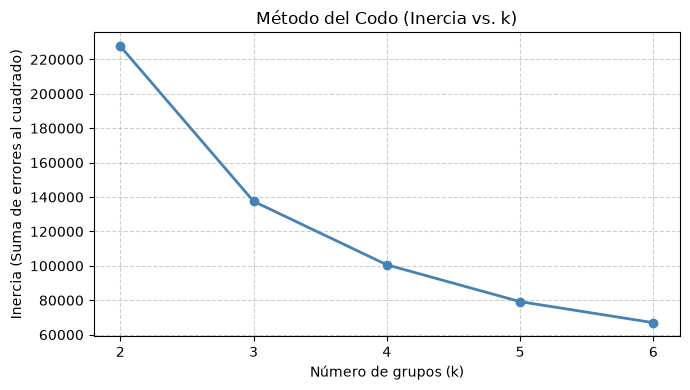

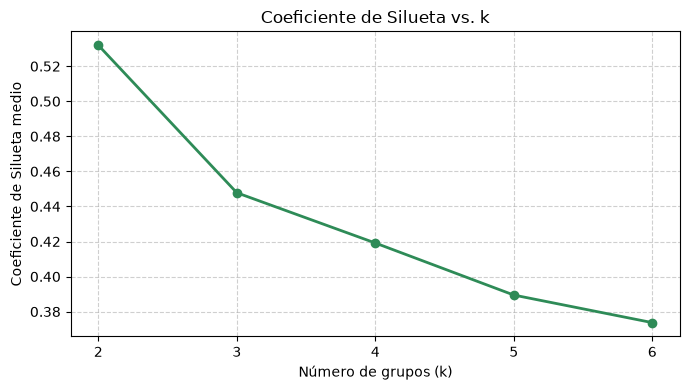

In [74]:
print("Tabla comparativa de métricas")
display(df_metricas.round(4))

# 6. Generar dos gráficas separadas
# Gráfica 1: Método del Codo (Inercia)
plt.figure(figsize=(7, 4))
plt.plot(df_metricas["k"], df_metricas["Inercia"], marker="o", color="steelblue", linewidth=2)
plt.title("Método del Codo (Inercia vs. k)")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia (Suma de errores al cuadrado)")
plt.xticks(valores_k)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfica 2: Coeficiente de Silueta
plt.figure(figsize=(7, 4))
plt.plot(df_metricas["k"], df_metricas["Silueta"], marker="o", color="seagreen", linewidth=2)
plt.title("Coeficiente de Silueta vs. k")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Coeficiente de Silueta medio")
plt.xticks(valores_k)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

In [75]:
#Elección de K
k_elegido = 3


In [76]:
# Entrenar modelo
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
grupos = modelo_final.fit_predict(X_escalado)

#  Guardar las etiquetas en el DataFrame original de viajes en efectivo
df_cash["Segmento"] = grupos

X_escalado.shape

(282085, 2)

In [77]:
# Generar gráfica de dispersión
# Tomamos una muestra de 5000 para visualización limpia sin saturar la gráfica
n_muestra = min(5000, len(X_escalado))
idx_muestra = X_escalado.sample(n=n_muestra, random_state=42).index

X_grafica = X_escalado.loc[idx_muestra]
etiquetas_grafica = df_cash.loc[idx_muestra, "Segmento"]

plt.figure(figsize=(9, 6))

<Figure size 900x600 with 0 Axes>

<Figure size 900x600 with 0 Axes>

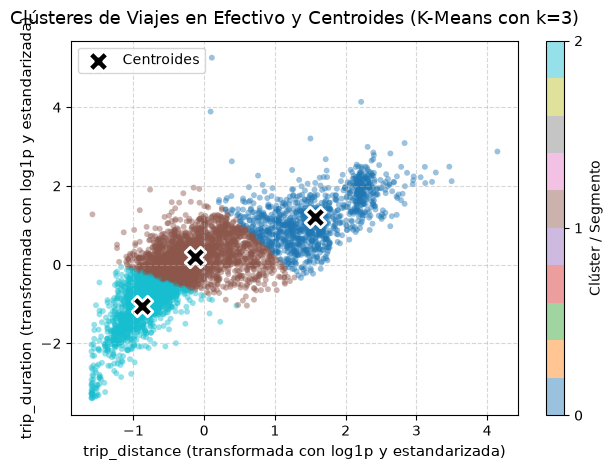

In [78]:
scatter = plt.scatter(
    X_grafica["trip_distance"], 
    X_grafica["trip_duration"], 
    c=etiquetas_grafica, 
    cmap="tab10", 
    s=18, 
    alpha=0.45,
    edgecolors="none"
)

# Centroides del modelo (marcadores X grandes y visibles)
centroides = modelo_final.cluster_centers_
plt.scatter(
    centroides[:, 0], 
    centroides[:, 1], 
    marker="X", 
    s=220, 
    c="black", 
    edgecolors="white", 
    linewidths=2, 
    label="Centroides"
)

# Agregar título, etiquetas de ejes, leyenda y formato
plt.title(f"Clústeres de Viajes en Efectivo y Centroides (K-Means con k={k_elegido})", fontsize=13, pad=12)
plt.xlabel("trip_distance (transformada con log1p y estandarizada)", fontsize=11)
plt.ylabel("trip_duration (transformada con log1p y estandarizada)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)

cbar = plt.colorbar(scatter, ticks=range(k_elegido))
cbar.set_label("Clúster / Segmento", fontsize=10)
plt.legend(loc="upper left", frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [79]:
# Crear copia 
df_resultado = df_cash.copy()

#  Agregar la columna cluster con las etiquetas del modelo final
df_resultado["cluster"] = grupos

#  Agrupar por cluster y calcular cantidad de viajes, medias y medianas
resumen_clusters = df_resultado.groupby("cluster").agg(
    viajes=("trip_distance", "size"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_minutos=("trip_duration", "mean"),
    duracion_mediana_minutos=("trip_duration", "median")
)

# Cálculo  de porcentaje del total de viajes
resumen_clusters["porcentaje_viajes"] = (resumen_clusters["viajes"] / len(df_resultado)) * 100

# 4. Mostrar la tabla con valores redondeados a dos decimales
print("--- Evidencia: Estadísticos por clúster (unidades originales) ---")
display(resumen_clusters.round(2))

--- Evidencia: Estadísticos por clúster (unidades originales) ---


,viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_minutos,duracion_mediana_minutos,porcentaje_viajes
cluster,,,,,,
0,62395,11.55,9.81,39.48,31.40,22.12
1,125521,2.30,1.94,15.43,14.00,44.50
2,94169,0.80,0.76,5.72,5.82,33.38


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**

Esta entre las opciones de 2 y 3, si se elige dos es separar los viajes en unicamente 2 categorias ( ejem rapidos / lentos)
 Lo cual los deja muy embiguos, en cambio con K = 3 termina la caida drastica de la inercia ( codo )
 y tiene una silueta que se puede estimar bien definida ( sin tanta redundancia entre grupos )
 
 <br>
 En resumen: k = 3 coincide con el punte de inflexion del codo y tiene una silueta adecuada
 que permite observar con buen nivel de detalle para poder analizar y obtener mas información de los datos.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

Clúster 2 – "Viajes Cortos": Concentra el 33.38% de los viajes. Se caracteriza por distancias y tiempos mínimos, con una mediana de 0.76 millas y 5.82 minutos de recorrido. Son trayectos breves dentro de un mismo vecindario o de pocas cuadras.

<br>

Clúster 1 – "Viajes Urbanos Estándar": Es el grupo mayoritario con el 44.50% de la demanda. Presenta un comportamiento intermedio, con una mediana de 1.94 millas y 14.00 minutos de duración. Representa el recorrido típico cotidiano en la ciudad, donde la congestión y los semáforos hacen que una distancia moderada tome un cuarto de hora.

<br>

Clúster 0 – "Viajes Largos": Reúne el 22.12% restante. Agrupa trayectos extensos, con una mediana de 9.81 millas y 31.40 minutos (alcanzando una media de casi 40 minutos debido al tráfico pesado). Corresponde a conexiones entre distritos distantes o salidas hacia aeropuertos, siendo los viajes de mayor impacto en tiempo y distancia.


**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**

El Clúster 0 (Viajes Largos o Metropolitanos) presenta la mayor duración promedio con 39.48 minutos (y una mediana de 31.40 minutos), superando ampliamente los 15.43 minutos del Clúster 1 y los 5.72 minutos del Clúster
<br>
este mismo grupo presenta también la mayor distancia promedio con 11.55 millas (mediana de 9.81 millas), frente a las 2.30 millas del Clúster 1 y las 0.80 millas del Clúster 2.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**

El grupo más numeroso es el Clúster 1 (Viajes Urbanos Estándar), el cual concentra 125,521 viajes, representando el 44.50% de todos los viajes pagados en efectivo analizados.
<br>
En este grupo predominan distancias y duraciones intermedias, con una distancia típica (mediana) de 1.94 millas (media de 2.30 millas) y una duración típica (mediana) de 14.00 minutos (media de 15.43 minutos).
<br>
Estos valores reflejan el servicio mas tradicional que hay en este tipo de negocio ( taxis ), traslados urbanos que debido a multiples factores como otros autos, semafotos, paradas etc. Toman en promedio de un cuarto de hora para completarse



---
### Lista de verificación antes de entregar

- [ X ] Se muestran la carga, exploración, limpieza y filtrado.
- [ X ] Se utilizaron las **dos variables indicadas**.
- [ X ] Se aplicaron `log1p` y `StandardScaler`.
- [ X ] Se calcularon inercia y silueta para `k = 2...6`.
- [ X ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ X ] Se visualizan los clústeres y sus centroides.
- [ X ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ X ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**